# TreeVibes: three-track training laboratory

One self-contained notebook: safely extract the dataset, preserve its annotations, create one locked grouped split, train a broad search, and compare the three project tracks.

**Executed locally on 31 October 2026:** 171 real-data trials completed (160 classical, seven neural, four portable quantized classifiers), with no failed trials. The standard preset used 3,806 curated field recordings. These are validation-selected weak-borer results; the final test remains untouched.

| Comparison | Selected model | Recall | FPR |
|---|---|---:|---:|
| A unrestricted | gaussian-nb / mfcc_pca16 | 49.74% | 4.79% |
| B export candidates (hardware pending) | int8-logistic-C1 / mfcc_flat | 14.60% | 4.79% |
| C 30x13 MFCC | gaussian-nb / mfcc_pca16 | 49.74% | 4.79% |
| B ∩ C | int8-logistic-C1 / mfcc_flat | 14.60% | 4.79% |

Selection maximizes recording recall subject to validation FPR ≤ 5%; another false-alarm allowance can change the winner. **No candidate has measured ESP32 qualification.** TensorFlow/TFLite training was not run because TensorFlow is not installed. The `full` preset plans 950 trials before optional TFLite and removes the standard training-window cap.

This executed run reused the available field recordings. Supplying the full original ZIP also extracts/inventories the laboratory files; their supervised training requires reviewed parent-recording lineage.

**Saved run:** `../outputs/treevibes-training-2026-10-31/treevibes-e473200d753cb0c9/`. Completed models, validation predictions, feature caches and exports are retained there.

| Track | Allowed information / model | Decision |
|---|---|---|
| A — unrestricted | Raw waveform, richer log-mel/spectral information; no model-size or inference budget filter | Highest validation recall at the chosen false-positive ceiling |
| B — ESP32 candidate | Compact portable classifier or fully integer TFLite; feature computation also counts | Best validation result among exportable candidates, then measured board qualification |
| C — data limited | **30 time frames × 13 MFCC coefficients per 1-second window**, exactly 390 values; any server model | Best validation result using only those values |

B and C are independent constraints. The notebook also reports their intersection and compact feature transmission alternatives. A finite experiment search is not proof of the best possible model. Local compute presets limit search effort, not the definition of Track A.

Labels are **weak folder-level borer acoustic annotations**. They do not establish species-confirmed red palm weevil (RPW) or tree health. Negative audio can come from infested trees. When supplied, the laboratory subset is extracted/inventoried but is excluded from supervised training until its parent-recording lineage is supplied.

Start with `PRESET='smoke'` to check the environment; use `standard` for a broad local search and `full` for the wider campaign. Run sequentially; neural training uses CUDA, Apple MPS, or CPU when available.


**ESP32 result interpretation:** B metrics below are Python validation of the quantized numerical reference. Independent compilation of the real C headers passed, but the selected MFCC C1 export changed one of 1,066 recording decisions relative to the Python reference because of finite-precision score/threshold rounding. Thus the exported threshold requires full decision-path parity checks on the target; no board-qualified result is claimed.


## 1. Setup and editable parameters

Install into the notebook kernel environment once. No installation runs automatically. Python 3.11 or newer is recommended.

```python
%pip install numpy scipy pandas scikit-learn soundfile matplotlib openpyxl joblib nbformat nbclient ipykernel
# Optional neural searches:
%pip install torch
# Optional fully integer TFLite training/export:
%pip install tensorflow
# Optional authenticated download (or supply an existing ZIP/root):
%pip install kagglehub
```

Kaggle credentials belong in the provider's normal credential store or environment, never in this notebook. Dataset: [potamitis/treevibes](https://www.kaggle.com/datasets/potamitis/treevibes). Label context: [original TreeVibes paper](https://www.mdpi.com/2624-6511/4/1/17). Integer export and memory requirements: [TFLite Micro](https://github.com/tensorflow/tflite-micro), [model conversion](https://github.com/tensorflow/tensorflow/blob/master/tensorflow/lite/g3doc/microcontrollers/build_convert.md).

The known local source path below is a convenience; replace it on another computer. `LABELS_CSV` can override workbook curation with explicit path/label/group_id/label_source columns. Include all known device/tree/site/session/parent and reviewed duplicate-group identifiers in optional columns so their shared ancestry is merged.


In [1]:
from pathlib import Path
import os

PRESET = os.environ.get('TREEVIBES_PRESET', 'standard')  # smoke / standard / full
SYNTHETIC_SMOKE = os.environ.get('TREEVIBES_SYNTHETIC', '0') == '1'
DATA_ROOT = Path(os.environ.get('TREEVIBES_DATA_ROOT',
    '/Users/khalidhamdan/Documents/Codex/2026-10-23/files-mentioned-by-the-user-codex/work/treevibes')).expanduser()
ARCHIVE = None  # e.g. Path('/path/to/treevibes.zip'); extracted only if DATA_ROOT does not exist
DOWNLOAD_IF_MISSING = False
LABELS_CSV = None  # optional explicit reviewed label manifest, paths relative to DATA_ROOT
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUTPUT_ROOT = Path(os.environ.get('TREEVIBES_OUTPUT_ROOT', str(PROJECT_ROOT / 'outputs/treevibes-training-2026-10-31'))).resolve()
RUN_NEURAL = True
RUN_TFLITE = False  # enable if TensorFlow is installed; explicit to avoid duplicate heavyweight runtimes
SEED = 42
FPR_CEILING = 0.05
AGGREGATION = 'mean'  # fixed before search; mean window probabilities per recording
# Every budget is an editable project allocation, NOT a board specification or measurement.
ESP_FLASH_MODEL_BUDGET = 256 * 1024
ESP_FIRMWARE_FLASH_BUDGET = 2 * 1024 * 1024  # editable full firmware allocation
ESP_RAM_BUDGET = 128 * 1024
ESP_LATENCY_BUDGET_MS = 100
ESP_ENERGY_BUDGET_MJ = 10
FINAL_TEST = False
FINAL_REVIEW_JSON = None  # reviewed, split-bound lineage sign-off; see final-test cell
FINAL_SELECTION_JSON = None  # frozen trial IDs and thresholds; see final-test cell

assert PRESET in {'smoke', 'standard', 'full'}
assert not SYNTHETIC_SMOKE or PRESET == 'smoke', 'Synthetic fixtures only support smoke mode'
BUDGET = {
    'smoke': dict(configs=1, max_train_windows=2, epochs=2, neural_widths=[8], seeds=[SEED]),
    'standard': dict(configs=2, max_train_windows=4, epochs=15, neural_widths=[16], seeds=[SEED]),
    'full': dict(configs=4, max_train_windows=None, epochs=50, neural_widths=[16, 32], seeds=[SEED, SEED+1, SEED+2]),
}[PRESET]
# Validation/test always use ALL windows. Training windows are evenly spaced if capped.
print('Preset:', PRESET, '| synthetic:', SYNTHETIC_SMOKE, '| training budget:', BUDGET)


Preset: standard | synthetic: False | training budget: {'configs': 2, 'max_train_windows': 4, 'epochs': 15, 'neural_widths': [16], 'seeds': [42]}


In [2]:
import csv, hashlib, inspect, json, math, platform, re, shutil, stat, sys, time, zipfile
from importlib import metadata, util
from math import gcd
import numpy as np
import pandas as pd
import soundfile as sf
from scipy.fft import dct
from scipy.signal import resample_poly
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier,
                              AdaBoostClassifier, GradientBoostingClassifier)
from sklearn.linear_model import LogisticRegression, SGDClassifier, RidgeClassifier
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier
import joblib
import matplotlib.pyplot as plt
from IPython.display import display

np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .2})

def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, default=str).encode()).hexdigest()

def file_hash(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, default=str, allow_nan=False) + '\n')

def atomic_joblib(value, path):
    temp = Path(str(path) + '.tmp')
    joblib.dump(value, temp)
    temp.replace(path)

VERSIONS = {p: metadata.version(p) for p in ['numpy', 'scipy', 'pandas', 'scikit-learn', 'soundfile', 'joblib']}
for package in ['torch','tensorflow']:
    try: VERSIONS[package] = metadata.version(package)
    except metadata.PackageNotFoundError: VERSIONS[package] = 'not installed'
# Bind scientific implementation; parameter values are recorded below.
# Exclude operational controls so releasing FINAL_TEST reuses the frozen campaign.
notebook_candidates = [Path(os.environ.get('TREEVIBES_NOTEBOOK_FILE','TreeVibes_Three_Track_Training.ipynb')),
                       Path('notebooks/TreeVibes_Three_Track_Training.ipynb')]
NOTEBOOK_FILE = next((p.resolve() for p in notebook_candidates if p.is_file()),None)
if NOTEBOOK_FILE is None:
    raise FileNotFoundError('Set TREEVIBES_NOTEBOOK_FILE to this notebook path for reproducible implementation hashing')
notebook_source = json.loads(NOTEBOOK_FILE.read_text())
IMPLEMENTATION_HASH = digest([''.join(c['source']) for c in notebook_source['cells'] if c['cell_type']=='code' and 'parameters' not in c.get('metadata',{}).get('tags',[])])
print(platform.platform(), sys.version.split()[0], VERSIONS)


macOS-26.6.2-arm64-arm-64bit 3.11.15 {'numpy': '2.4.6', 'scipy': '1.17.1', 'pandas': '3.1.0', 'scikit-learn': '1.9.1', 'soundfile': '0.14.0', 'joblib': '1.6.0', 'torch': '2.15.0', 'tensorflow': 'not installed'}


## 2. Download or safely extract; inventory everything

Extraction rejects absolute paths, traversal, symlinks, excessive expanded size and conflicting existing files. It does not overwrite source audio. An extraction receipt is written only after every file has completed. If interrupted, rerun: existing files must match their ZIP CRC and size. A prepared directory works without downloading again.

The supervised default uses the field WAV subset and workbook `AUDIO` labels. Folder 35 and difficult/unknown folders remain excluded because their parent lineage is unresolved. No directory name such as “infested” is automatically converted into a biological species label.


In [3]:
def safe_extract(archive, destination, max_expanded_bytes=30_000_000_000):
    destination = Path(destination).resolve()
    with zipfile.ZipFile(archive) as z:
        members = z.infolist()
        if sum(m.file_size for m in members) > max_expanded_bytes:
            raise ValueError('Archive exceeds expanded-size allowance')
        seen = set()
        for member in members:
            name = member.filename.replace('\\', '/')
            parts = Path(name).parts
            target = (destination / name).resolve()
            mode = member.external_attr >> 16
            if (name.startswith('/') or re.match(r'^[A-Za-z]:', name) or '..' in parts
                    or not target.is_relative_to(destination) or stat.S_ISLNK(mode)):
                raise ValueError('Unsafe archive entry: ' + name)
            if name in seen:
                raise ValueError('Duplicate archive destination: ' + name)
            seen.add(name)
        destination.mkdir(parents=True, exist_ok=True)
        import zlib
        for member in members:
            target = destination / member.filename.replace('\\', '/')
            if member.is_dir():
                target.mkdir(parents=True, exist_ok=True)
                continue
            target.parent.mkdir(parents=True, exist_ok=True)
            if target.exists():
                crc = 0
                with target.open('rb') as handle:
                    for block in iter(lambda: handle.read(1024 * 1024), b''):
                        crc = zlib.crc32(block, crc)
                if target.stat().st_size != member.file_size or crc != member.CRC:
                    raise ValueError('Conflicting existing extracted file: ' + str(target))
                continue
            temp = target.with_name(target.name + '.extracting')
            with z.open(member) as source, temp.open('wb') as output:
                shutil.copyfileobj(source, output, 1024 * 1024)
            temp.replace(target)
    write_json(destination / 'extraction_receipt.json',
               {'archive_sha256': file_hash(archive), 'entries': len(members), 'complete': True})

def make_synthetic_fixture(root):
    root.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(SEED)
    rows = []
    for group in range(18):
        for label in (0, 1):
            for clip in range(2):
                t = np.arange(16000) / 8000
                x = .025 * rng.normal(size=len(t))
                x += (.045 + .01*rng.random()) * np.sin(2*np.pi*(350+label*1100+group)*t)
                name = f'group_{group}/label_{label}_{clip}.wav'
                path = root / name
                path.parent.mkdir(exist_ok=True)
                sf.write(path, x, 8000, subtype='PCM_16')
                rows.append({'path': name, 'label': label, 'group_id': f'synthetic-{group}',
                             'label_source': 'SYNTHETIC SOFTWARE CHECK; not TreeVibes'})
    path = root / 'synthetic_labels.csv'
    pd.DataFrame(rows).to_csv(path, index=False)
    return path

if SYNTHETIC_SMOKE:
    DATA_ROOT = OUTPUT_ROOT / 'synthetic_fixture'
    LABELS_CSV = make_synthetic_fixture(DATA_ROOT)
elif not DATA_ROOT.exists():
    if ARCHIVE is not None:
        safe_extract(ARCHIVE, DATA_ROOT)
    elif DOWNLOAD_IF_MISSING:
        import kagglehub
        DATA_ROOT = Path(kagglehub.dataset_download('potamitis/treevibes'))
    else:
        raise FileNotFoundError('Set DATA_ROOT, ARCHIVE, or DOWNLOAD_IF_MISSING before running')

# Handle one enclosing ZIP directory without guessing labels.
workbooks = list(DATA_ROOT.rglob('TreeVibes.xlsx'))
if LABELS_CSV is None:
    if len(workbooks) != 1:
        raise ValueError(f'Expected one TreeVibes.xlsx; found {len(workbooks)}. Supply LABELS_CSV explicitly.')
    DATA_ROOT = workbooks[0].parent
inventory = pd.Series([p.suffix.lower() or '(no extension)' for p in DATA_ROOT.rglob('*') if p.is_file()]).value_counts()
display(inventory.rename('files').to_frame())
print('Dataset root:', DATA_ROOT)


,files
.wav,4154
.txt,2
.xlsx,1


Dataset root: /Users/khalidhamdan/Documents/Codex/2026-10-23/files-mentioned-by-the-user-codex/work/treevibes


In [4]:
def workbook_labels(root):
    from openpyxl import load_workbook
    records = {}
    for row in load_workbook(root / 'TreeVibes.xlsx', data_only=True).active.iter_rows(min_row=2, values_only=True):
        if row[0] and re.fullmatch(r'folder_\d+', str(row[0])):
            records[str(row[0])] = {'device': str(row[1]), 'site': (row[2], row[3]), 'audio': row[5]}
    labels, excluded = [], []
    for path in sorted(root.rglob('*')):
        if path.suffix.lower() != '.wav' or 'field' not in [p.lower() for p in path.parts]:
            continue
        rel = path.relative_to(root).as_posix()
        matches = re.findall(r'(?:^|/)folder_(\d+)(?:/|$)', rel)
        folder = 'folder_' + matches[0] if matches else None
        rec = records.get(folder)
        if rec is None or folder == 'folder_35':
            excluded.append({'path': rel, 'reason': 'unknown/ambiguous parent lineage'})
            continue
        if rec['audio'] not in (0, 1):
            raise ValueError('Nonbinary AUDIO annotation in ' + folder)
        # Hash identifiers to avoid copying device IDs / coordinates into shared reports.
        device = rec['device'].strip()
        device_id = digest(device)[:16] if device not in {'None', 'NA', 'nan', ''} else ''
        site_id = digest(rec['site'])[:16] if all(isinstance(v, (int, float)) and np.isfinite(v) and abs(v) <= limit for v, limit in zip(rec['site'], (90, 180))) else ''
        labels.append({'path': rel, 'label': int(rec['audio']), 'group_id': folder,
                       'device_id': device_id, 'site_id': site_id,
                       'label_source': 'TreeVibes.xlsx AUDIO; weak folder annotation; species unverified'})
    return pd.DataFrame(labels), pd.DataFrame(excluded)

if LABELS_CSV is not None:
    labels = pd.read_csv(LABELS_CSV, dtype={'path': str, 'group_id': str, 'label_source': str})
    exclusions = pd.DataFrame(columns=['path', 'reason'])
else:
    labels, exclusions = workbook_labels(DATA_ROOT)
required = {'path', 'label', 'group_id', 'label_source'}
assert required.issubset(labels), f'Label CSV requires {required}'
assert len(labels) and not labels['path'].duplicated().any()
assert set(labels.label) == {0, 1}, 'Both binary classes required'
assert labels[['group_id', 'label_source']].notna().all().all()
assert labels.group_id.astype(str).str.strip().ne('').all()
print('Included:', len(labels), '| excluded:', len(exclusions), '| weak labels:', labels.label.value_counts().to_dict())


Included: 3806 | excluded: 348 | weak labels: {1: 2385, 0: 1421}


## 3. Audit audio and merge shared ancestry before splitting

The union of shared `group_id`, device, site, tree, session, parent-recording, reviewed duplicate-group identifiers and identical decoded-PCM hashes defines independence. Supplying stronger ancestry in the CSV automatically makes the split stricter. The notebook refuses to fall back to random windows when independent class groups are insufficient.

Exact hashes do not find every near-duplicate. A diagnostic nearest-neighbour list is saved after feature extraction; final-test release additionally requires a human review bound to this manifest and split. Repeatedly searching validation can overfit it, especially with few independent devices/sites.


In [5]:
def load_audio(path):
    x, sr = sf.read(path, dtype='float64', always_2d=True)
    if not len(x) or not np.isfinite(x).all():
        raise ValueError('Invalid audio: ' + str(path))
    x = x.mean(axis=1)
    if sr != 8000:
        divisor = gcd(int(sr), 8000)
        x = resample_poly(x, 8000 // divisor, int(sr) // divisor)
    return x

rows = []
for row in labels.to_dict('records'):
    relative = str(row['path']).replace('\\', '/')
    path = (DATA_ROOT / relative).resolve()
    if Path(relative).is_absolute() or '..' in Path(relative).parts or not path.is_relative_to(DATA_ROOT.resolve()):
        raise ValueError('Unsafe manifest path: ' + relative)
    x, sr = sf.read(path, dtype='float64', always_2d=True)
    if not len(x) or not np.isfinite(x).all():
        raise ValueError('Empty/nonfinite audio: ' + relative)
    row.update(path=relative, absolute_path=str(path), file_sha256=file_hash(path),
               pcm_sha256=hashlib.sha256(f'{sr}:{x.shape[1]}:'.encode()+x.astype('<f8').tobytes()).hexdigest(),
               duration_seconds=len(x)/sr, sample_rate=sr, channels=x.shape[1],
               rms=float(np.sqrt(np.mean(x*x))), clipping_fraction=float(np.mean(abs(x)>=.999)))
    rows.append(row)
manifest = pd.DataFrame(rows)
if (manifest.groupby('pcm_sha256').label.nunique() > 1).any():
    raise ValueError('Conflicting labels on identical decoded audio; review before training')
parents = list(range(len(manifest)))
def find(i):
    while parents[i] != i:
        parents[i] = parents[parents[i]]
        i = parents[i]
    return i
seen = {}
for i, row in manifest.iterrows():
    for field in ['group_id', 'device_id', 'site_id', 'tree_id', 'session_id', 'parent_recording_id', 'duplicate_group_id', 'pcm_sha256']:
        value = row.get(field)
        if pd.isna(value) or str(value).strip() in {'', 'None', 'NA', 'nan'}:
            continue
        key = field, str(value)
        if key in seen:
            parents[find(i)] = find(seen[key])
        else:
            seen[key] = i
manifest['component'] = [f'component-{find(i):06d}' for i in range(len(manifest))]
MANIFEST_HASH = digest(manifest.drop(columns='absolute_path').fillna('').to_dict('records'))
CAMPAIGN_CONFIG = dict(preset=PRESET, synthetic=SYNTHETIC_SMOKE, seed=SEED, budget=BUDGET,
                       fpr_ceiling=FPR_CEILING, aggregation=AGGREGATION, versions=VERSIONS,
                       protocol='treevibes-three-track-v1', manifest_sha256=MANIFEST_HASH,
                       implementation_sha256=IMPLEMENTATION_HASH,
                       esp_allocations=dict(model_flash=ESP_FLASH_MODEL_BUDGET,firmware_flash=ESP_FIRMWARE_FLASH_BUDGET,
                           peak_ram=ESP_RAM_BUDGET,latency_ms=ESP_LATENCY_BUDGET_MS,energy_mj=ESP_ENERGY_BUDGET_MJ))
RUN = OUTPUT_ROOT / (('SYNTHETIC-' if SYNTHETIC_SMOKE else 'treevibes-') + digest(CAMPAIGN_CONFIG)[:16])
RUN.mkdir(parents=True, exist_ok=True)
write_json(RUN / 'config.json', CAMPAIGN_CONFIG)
manifest.drop(columns='absolute_path').to_csv(RUN / 'manifest.csv', index=False)
exclusions.to_csv(RUN / 'exclusions.csv', index=False)
print('Run:', RUN, '| independent components:', manifest.component.nunique())
display(manifest.groupby('label').agg(recordings=('path', 'size'), components=('component', 'nunique'),
                                      median_duration_s=('duration_seconds', 'median')))


Run: /Users/khalidhamdan/Documents/ChatGPT/SPD 2 Simulation/outputs/treevibes-training-2026-10-31/treevibes-e473200d753cb0c9 | independent components: 7


,recordings,components,median_duration_s
label,,,
0,1421,3,20.479
1,2385,6,20.480


In [6]:
def grouped_pick(indices, fraction, seed):
    best = None
    y = manifest.label.to_numpy()
    groups = manifest.component.to_numpy()
    splitter = GroupShuffleSplit(n_splits=256, test_size=fraction, random_state=seed)
    for a, b in splitter.split(indices, y[indices], groups[indices]):
        a, b = indices[a], indices[b]
        if len(set(y[a])) != 2 or len(set(y[b])) != 2:
            continue
        penalty = abs(len(b)/len(indices)-fraction) + abs(y[a].mean()-y[indices].mean()) + abs(y[b].mean()-y[indices].mean())
        if best is None or penalty < best[0]:
            best = penalty, a, b
    if best is None:
        raise ValueError('Insufficient independent components with both classes; review groups, never split windows randomly')
    return best[1], best[2]

split_file = RUN / 'splits.csv'
lock_file = RUN / 'split_lock.json'
if split_file.exists() != lock_file.exists():
    raise ValueError('Incomplete split lock; inspect run directory rather than regenerating it')
if split_file.exists():
    locked = pd.read_csv(split_file)
    lock = json.loads(lock_file.read_text())
    assert lock['manifest_sha256'] == MANIFEST_HASH and lock['split_sha256'] == file_hash(split_file)
    assert locked.path.tolist() == manifest.path.tolist()
    manifest['split'] = locked['split']
else:
    dev_idx, test_idx = grouped_pick(np.arange(len(manifest)), .2, SEED)
    train_idx, val_idx = grouped_pick(dev_idx, .25, SEED+1)
    manifest['split'] = ''
    for name, idx in [('train', train_idx), ('val', val_idx), ('test', test_idx)]:
        manifest.loc[idx, 'split'] = name
    manifest[['path', 'label', 'component', 'pcm_sha256', 'split']].to_csv(split_file, index=False)
    lock = dict(manifest_sha256=MANIFEST_HASH, split_sha256=file_hash(split_file), seed=SEED,
                method='grouped 60/20/20 candidates, selected by label balance only; no model scores')
    write_json(lock_file, lock)
for field in ['path', 'component', 'pcm_sha256']:
    assert manifest.groupby(field)['split'].nunique().max() == 1, 'Cross-split leakage: ' + field
for name in ['train', 'val', 'test']:
    assert set(manifest.loc[manifest.split == name, 'label']) == {0, 1}
SPLIT_HASH = lock['split_sha256']
display(pd.crosstab(manifest.split, manifest.label).rename(columns={0:'weak negative', 1:'weak positive'}))
print('Locked split:', SPLIT_HASH, '| test labels are audited for balance; no test model scores are used in search')


label,weak negative,weak positive
split,,
test,446,818
train,683,793
val,292,774


Locked split: b1a1c2e8cf9e6e8d50c37f03f29a7cc0b1b5ef27504e16ed78d719b7e00a67fc | test labels are audited for balance; no test model scores are used in search


## 4. Extract features once; preserve the exact 30 × 13 protocol

The MFCC branch uses the earlier `mfcc-8k-30x13-v1` protocol: 8 kHz mono, nonoverlapping 8,000-sample windows, periodic Hann 512, hop 256, 40 HTK mel filters, natural log floor 1e−10, orthonormal DCT-II, first 13 coefficients. Thirty frames end at sample 7,936; the last 64 samples are unused. Final partial windows are zero-padded.

Track A also sees log-mel sequences (64 filters, 128-sample hop), raw waveforms and richer spectral/impulse summaries. These are runnable alternatives, not extra information secretly added to Track C. No per-recording label is used to pick loud/positive windows. The cap affects training only; all validation/test windows contribute to the fixed recording average.

Feature files are keyed by the source manifest, split, protocol, and training-window policy. No test features are loaded/extracted during the search. Exact packet sizes: 390 float32 = 1,560 bytes; 390 int8 = 390 bytes plus the required scale/version metadata. Transport fragmentation and radio energy must be assessed separately.


In [7]:
MFCC_SPEC = {'sample_rate':8000, 'window_samples':8000, 'n_fft':512, 'hop':256,
             'frames':30, 'mel_filters':40, 'coefficients':13, 'floor':1e-10,
             'mel_scale':'HTK', 'window':'periodic Hann', 'dct':'II ortho', 'version':'mfcc-8k-30x13-v1'}
WINDOW = np.hanning(513)[:-1]
def mel_bank(count):
    hz = 700 * (10**(np.linspace(0, 2595*np.log10(1+4000/700), count+2)/2595)-1)
    freq = np.arange(257)*8000/512
    return np.maximum(0, np.minimum((freq[None]-hz[:-2,None])/(hz[1:-1,None]-hz[:-2,None]),
                                   (hz[2:,None]-freq[None])/(hz[2:,None]-hz[1:-1,None])))
MEL40, MEL64 = mel_bank(40), mel_bank(64)
DCT13 = dct(np.eye(40), type=2, norm='ortho', axis=0)[:13]
def frame_power(audio, hop, frames):
    chunks = np.stack([audio[i*hop:i*hop+512] for i in range(frames)])
    return abs(np.fft.rfft(chunks*WINDOW, axis=1))**2/512

def window_features(audio):
    assert audio.shape == (8000,) and np.isfinite(audio).all()
    power = frame_power(audio, 256, 30)
    mfcc = (np.log(np.maximum(power @ MEL40.T, 1e-10)) @ DCT13.T).astype('float32')
    logmel = np.log(np.maximum(frame_power(audio, 128, 59) @ MEL64.T, 1e-10)).astype('float32')
    spectrum = abs(np.fft.rfft(audio))**2
    freq = np.fft.rfftfreq(len(audio), 1/8000)
    norm = spectrum / max(spectrum.sum(), 1e-20)
    band = np.array([spectrum[(freq>=a)&(freq<b)].sum() for a,b in [(0,250),(250,500),(500,1000),(1000,2000),(2000,4001)]])
    rms = np.sqrt(np.mean(audio**2))
    pulse = np.mean(abs(audio) > 3*max(rms,1e-10))
    summary = np.r_[mfcc.mean(0),mfcc.std(0),mfcc.min(0),mfcc.max(0),
                    np.sqrt(np.mean(audio**2)), np.max(abs(audio)), np.mean(audio[:-1]*audio[1:]<0),
                    (freq*norm).sum(), np.sqrt(((freq-(freq*norm).sum())**2*norm).sum()),
                    pulse, np.log1p(band)]
    return mfcc, logmel, summary.astype('float32')

def extract_indices(indices, training=False):
    key = digest(dict(manifest=MANIFEST_HASH, split=SPLIT_HASH, spec=MFCC_SPEC,
                      feature_version='raw-logmel-summary-v1', indices=list(map(int,indices)),
                      cap=BUDGET['max_train_windows'] if training else None))[:20]
    cache = RUN / ('features-' + key + '.npz')
    if cache.exists():
        with np.load(cache, allow_pickle=False) as data:
            return {k:data[k] for k in data.files}
    arrays = {k:[] for k in ['mfcc','logmel','rich','raw','record_id','label']}
    for rid in indices:
        row = manifest.iloc[int(rid)]
        audio = load_audio(row.absolute_path)
        chunks = np.pad(audio, (0, (-len(audio))%8000)).reshape(-1,8000)
        selected = np.arange(len(chunks))
        cap = BUDGET['max_train_windows'] if training else None
        if cap is not None and len(selected)>cap:
            selected = np.unique(np.linspace(0,len(chunks)-1,cap,dtype=int))
        for j in selected:
            m,l,s = window_features(chunks[j])
            arrays['mfcc'].append(m); arrays['logmel'].append(l); arrays['rich'].append(s)
            arrays['raw'].append(chunks[j].astype('float32'))
            arrays['record_id'].append(int(rid)); arrays['label'].append(int(row.label))
    result = {k:np.asarray(v) for k,v in arrays.items()}
    np.savez_compressed(cache, **result)
    return result

train_ids = np.flatnonzero(manifest.split.to_numpy()=='train')
val_ids = np.flatnonzero(manifest.split.to_numpy()=='val')
train = extract_indices(train_ids, training=True)
val = extract_indices(val_ids)
assert train['mfcc'].shape[1:] == (30,13)
assert set(train['record_id']).isdisjoint(val['record_id'])
write_json(RUN / 'feature_protocol.json', MFCC_SPEC)
print('Training windows:',len(train['label']),'| validation windows:',len(val['label']))


Training windows: 5904 | validation windows: 22252


### Near-duplicate diagnostic and self-checks

A compact fingerprint retrieves suspicious cross-group pairs for review; it is not a complete duplicate detector or proof of biological independence. Test audio is not fingerprinted here. Before final evaluation, review original-file ancestry across the entire manifest without inspecting model errors or test scores. If review changes grouping, create a new manifest/campaign and retire the old split.


In [8]:
# Diagnostic: recording-mean spectral summaries from development data only.
all_dev = pd.DataFrame(np.vstack([train['rich'],val['rich']]))
all_dev['record_id'] = np.r_[train['record_id'],val['record_id']]
fingerprint = all_dev.groupby('record_id').mean()
scaled = StandardScaler().fit_transform(fingerprint)  # diagnostic only; never a model transform
neighbors = NearestNeighbors(n_neighbors=min(6,len(scaled)),n_jobs=1).fit(scaled)
distance, nearby = neighbors.kneighbors(scaled)
candidates = []
for i in range(len(scaled)):
    for dist,j in zip(distance[i,1:],nearby[i,1:]):
        a,b = int(fingerprint.index[i]),int(fingerprint.index[j])
        if a<b and manifest.iloc[a].component != manifest.iloc[b].component:
            candidates.append({'path_a':manifest.iloc[a].path,'path_b':manifest.iloc[b].path,
                               'distance':float(dist),'decision':'UNREVIEWED','evidence':''})
near_duplicates = pd.DataFrame(candidates).sort_values('distance').head(100) if candidates else pd.DataFrame()
near_duplicates.to_csv(RUN/'near_duplicate_candidates.csv', index=False)
assert window_features(np.zeros(8000))[0].shape == (30,13)
assert np.isfinite(window_features(np.zeros(8000))[0]).all()
assert digest({'a':1,'b':2}) == digest({'b':2,'a':1})
print('Self-checks passed. Development near-duplicate candidates:',len(near_duplicates))


Self-checks passed. Development near-duplicate candidates: 64


## 5. Metrics, recording aggregation and operating point

Rank by **recording recall at validation FPR ≤ 5%** (editable above), then average precision, then F1. Precision, accuracy, AUROC, AP, F1 and raw confusion counts remain visible. The threshold is selected on validation only. If the ceiling admits no positive predictions, recall is zero rather than a fabricated success. A tiny negative denominator cannot establish a precise population FPR.

The same recording mean pools all window probabilities. Score-only classifiers are mapped through a sigmoid solely to obtain monotonic comparable window scores; these are not calibrated probabilities. Each classifier's threshold absorbs its scale. Search results are validation screening, not final test performance.


In [9]:
def record_scores(scores, dataset):
    frame = pd.DataFrame({'record_id':dataset['record_id'],'label':dataset['label'],'score':np.asarray(scores).reshape(-1)})
    assert np.isfinite(frame.score).all()
    if AGGREGATION != 'mean':
        raise ValueError('Only prespecified mean pooling is implemented')
    return frame.groupby('record_id', sort=True).agg(label=('label','first'),score=('score','mean')).reset_index()

def metrics_at(y, p, threshold):
    pred = np.asarray(p) >= threshold
    tn,fp,fn,tp = confusion_matrix(y,pred,labels=[0,1]).ravel()
    return dict(threshold=float(threshold), recall=float(recall_score(y,pred,zero_division=0)),
                precision=float(precision_score(y,pred,zero_division=0)), f1=float(f1_score(y,pred,zero_division=0)),
                accuracy=float(accuracy_score(y,pred)), fpr=float(fp/max(tn+fp,1)),
                average_precision=float(average_precision_score(y,p)), auroc=float(roc_auc_score(y,p)),
                tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp), recordings=len(y))

def choose_threshold(y, p):
    fpr,tpr,thresholds = roc_curve(y,p,drop_intermediate=False)
    # Scores are probabilities. An exactly representable sentinel survives float32 C export.
    thresholds[~np.isfinite(thresholds)] = 2.0
    valid = np.flatnonzero(fpr <= FPR_CEILING+1e-12)
    best = max(valid,key=lambda i:(tpr[i],-fpr[i],thresholds[i]))
    return metrics_at(y,p,float(thresholds[best]))

def model_scores(model, x):
    if hasattr(model,'predict_proba'):
        return model.predict_proba(x)[:,list(model.classes_).index(1)]
    score = model.decision_function(x)
    return 1/(1+np.exp(-np.clip(score,-40,40)))

def evaluate_scores(scores, dataset=val, threshold=None):
    table = record_scores(scores,dataset)
    result = choose_threshold(table.label.to_numpy(),table.score.to_numpy()) if threshold is None else metrics_at(table.label,table.score,threshold)
    return result,table

# Threshold and grouping checks use known small fixtures, not the benchmark.
check = choose_threshold(np.array([0,0,1,1]),np.array([.1,.2,.8,.9]))
assert check['recall']==1 and check['fpr']==0
assert record_scores([.1,.3,.8],{'record_id':np.array([1,1,2]),'label':np.array([0,0,1])}).score.tolist()==[.2,.8]

# Predict-none must remain above all probabilities after float32 export.
assert choose_threshold(np.array([0,0,1,1]), np.full(4, 1e-10))['threshold'] == 2.0


## 6. Broad classical search: unrestricted and data-limited models

Families: dummy, logistic regression, linear SVM, RBF SVM, polynomial SVM, SGD logistic, ridge classifier, Gaussian naive Bayes, linear/quadratic discriminant analysis, k-nearest neighbours, decision tree, random forest, extra trees, histogram gradient boosting, gradient boosting, AdaBoost and MLP.

Representations: richer acoustic summary (A), exact flattened MFCC (C), 26 MFCC mean/std features (C, compact transmission), and train-fitted PCA16/PCA32 of the MFCC vector (C). PCA/transforms are fit only on training windows. The flat 390-vector preserves the full limited input. No MFCC-only candidate receives rich/raw/log-mel data.

The printed matrix is the actual planned search. Failed trials are logged with their error and never ranked as successes. A completed trial resumes only when its data/split/config/version identity matches. Interrupt between trials to stop safely; already-finished artifacts remain reusable. Full RBF/polynomial SVM can be expensive with all windows; this is a visible cost of the chosen search.


In [10]:
def classical_candidates(seed):
    n = BUDGET['configs']
    cvalues = [.1,1,10,100][:n]
    candidates = [('dummy',DummyClassifier(strategy='prior'))]
    for c in cvalues:
        candidates += [(f'logistic-C{c}',LogisticRegression(C=c,max_iter=2000,class_weight='balanced',random_state=seed)),
                       (f'linear-svm-C{c}',LinearSVC(C=c,max_iter=5000,class_weight='balanced',random_state=seed)),
                       (f'rbf-svm-C{c}',SVC(C=c,kernel='rbf',class_weight='balanced',cache_size=512)),
                       (f'poly-svm-C{c}',SVC(C=c,kernel='poly',degree=2,class_weight='balanced',cache_size=512)),
                       (f'ridge-{c}',RidgeClassifier(alpha=c,class_weight='balanced'))]
    for alpha in [1e-4,1e-3,1e-2,.1][:n]:
        candidates.append((f'sgd-{alpha}',SGDClassifier(loss='log_loss',alpha=alpha,class_weight='balanced',max_iter=2000,random_state=seed)))
    candidates += [('gaussian-nb',GaussianNB()),('lda',LinearDiscriminantAnalysis(solver='lsqr',shrinkage='auto')),
                   ('qda',QuadraticDiscriminantAnalysis(reg_param=.2))]
    for k in [3,7,15,31][:n]:
        candidates.append((f'knn-{k}',KNeighborsClassifier(n_neighbors=k,n_jobs=1)))
    for depth in [3,6,12,None][:n]:
        label = str(depth)
        candidates += [(f'tree-{label}',DecisionTreeClassifier(max_depth=depth,min_samples_leaf=3,class_weight='balanced',random_state=seed)),
                       (f'random-forest-{label}',RandomForestClassifier(n_estimators=150,max_depth=depth,min_samples_leaf=2,class_weight='balanced',n_jobs=1,random_state=seed)),
                       (f'extra-trees-{label}',ExtraTreesClassifier(n_estimators=150,max_depth=depth,min_samples_leaf=2,class_weight='balanced',n_jobs=1,random_state=seed))]
    for lr in [.03,.1,.2,.3][:n]:
        candidates += [(f'hist-boost-{lr}',HistGradientBoostingClassifier(learning_rate=lr,max_iter=150,early_stopping=False,random_state=seed)),
                       (f'gradient-boost-{lr}',GradientBoostingClassifier(learning_rate=lr,n_estimators=100,random_state=seed)),
                       (f'adaboost-{lr}',AdaBoostClassifier(learning_rate=lr,n_estimators=100,random_state=seed))]
    for hidden in [(32,),(64,32),(128,64),(256,128,32)][:n]:
        # No random internal validation split: stopping uses training loss here.
        candidates.append((f'mlp-{hidden}',MLPClassifier(hidden_layer_sizes=hidden,max_iter=300,early_stopping=False,random_state=seed)))
    if PRESET=='smoke':
        candidates = [(name,model) for name,model in candidates if name in {'dummy','logistic-C0.1','tree-3'}]
    return candidates

REPRESENTATIONS = ['rich','mfcc_flat','mfcc_summary','mfcc_pca16','mfcc_pca32']
if PRESET=='smoke':
    REPRESENTATIONS = ['rich','mfcc_flat']

def representation(name, dataset):
    if name=='rich': return dataset['rich']
    if name=='mfcc_summary': return np.concatenate([dataset['mfcc'].mean(1),dataset['mfcc'].std(1)],axis=1)
    return dataset['mfcc'].reshape(len(dataset['label']),-1)

def classical_pipeline(name, classifier):
    steps = [('scale',StandardScaler())]
    if name.startswith('mfcc_pca'):
        components = min(int(name.split('pca')[1]),len(train['label']),390)
        steps.append(('pca',PCA(n_components=components,random_state=SEED)))
    steps.append(('classifier',clone(classifier)))
    return Pipeline(steps)

plan = [(seed,rep,name) for seed in BUDGET['seeds'] for rep in REPRESENTATIONS for name,_ in classical_candidates(seed)]
print('Planned classical trials:',len(plan),'| representations:',REPRESENTATIONS,
      '| model families:',len({name.split('-')[0] for _,_,name in plan}))
TRIALS = RUN/'trials'
TRIALS.mkdir(exist_ok=True)

def trial_identity(spec):
    return digest({'campaign':CAMPAIGN_CONFIG,'split':SPLIT_HASH,'spec':spec})[:24]

def store_trial(spec, result, predictions, bundle):
    trial_id = trial_identity(spec)
    path = TRIALS/trial_id
    path.mkdir(exist_ok=True)
    predictions.to_csv(path/'validation_predictions.csv',index=False)
    atomic_joblib(bundle,path/'model.joblib')
    row = dict(trial_id=trial_id,**spec,**result,status='complete',label_semantics='weak borer; RPW unverified',
               synthetic=SYNTHETIC_SMOKE,esp_qualified=False)
    write_json(path/'result.json',row)  # completion marker is written last
    return row

for seed in BUDGET['seeds']:
    for rep in REPRESENTATIONS:
        xtr,xval = representation(rep,train),representation(rep,val)
        for name,classifier in classical_candidates(seed):
            spec = dict(kind='classical',name=name,representation=rep,seed=seed,track='A' if rep=='rich' else 'C',
                        esp_candidate=False)
            trial_id = trial_identity(spec)
            path = TRIALS/trial_id
            if (path/'result.json').exists():
                continue
            start=time.perf_counter()
            try:
                model=classical_pipeline(rep,classifier)
                model.fit(xtr,train['label'])
                result,predictions=evaluate_scores(model_scores(model,xval))
                result['training_seconds']=time.perf_counter()-start
                result['host_model_bytes']=len(__import__('pickle').dumps(model,protocol=5))
                store_trial(spec,result,predictions,{'model':model,'representation':rep,'threshold':result['threshold'],
                    'manifest_sha256':MANIFEST_HASH,'split_sha256':SPLIT_HASH,'feature_protocol':MFCC_SPEC})
            except Exception as error:
                path.mkdir(exist_ok=True)
                write_json(path/'failure.json',dict(spec=spec,error=repr(error),elapsed_seconds=time.perf_counter()-start))
                print('Failed:',rep,name,repr(error)[:160])
print('Classical search finished; completed:',len(list(TRIALS.glob('*/result.json'))))


Planned classical trials: 160 | representations: ['rich', 'mfcc_flat', 'mfcc_summary', 'mfcc_pca16', 'mfcc_pca32'] | model families: 18


Classical search finished; completed: 160


## 7. Neural searches: raw CNN, log-mel CNN/residual CNN/CRNN, MFCC MLP/CNN/GRU

These networks train from scratch; they do not require downloaded pretrained weights. A and C retain separate inputs. Validation recording AP selects the epoch, and the final operating point is then chosen on validation. Optimizer, epoch count, architecture width and random seed are recorded. Validation is consequently development data, never an unbiased final estimate.

The network sees one 1-second window at a time with weak inherited recording labels; recording-level scores pool all windows. This is a useful baseline, but not a claim of event-level labels. Class weighting addresses class imbalance; the training window cap also limits long-recording dominance. GPU availability changes speed, not which track a model belongs to.


In [11]:
TORCH_AVAILABLE = util.find_spec('torch') is not None
NEURAL_SPECS = [('raw_cnn','raw','A'),('logmel_cnn','logmel','A'),('logmel_resnet','logmel','A'),('logmel_crnn','logmel','A'),
                ('mfcc_mlp','mfcc','C'),('mfcc_cnn','mfcc','C'),('mfcc_gru','mfcc','C')]
if PRESET=='smoke': NEURAL_SPECS = [('mfcc_mlp','mfcc','C')]
if TORCH_AVAILABLE:
    import torch
    from torch import nn
    from torch.utils.data import DataLoader,TensorDataset
    torch.set_num_threads(max(1,min(4,os.cpu_count() or 1)))
    device=torch.device('cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu'))
    print('Torch:',torch.__version__,'| device:',device)

    class ResidualBlock(nn.Module):
        def __init__(self,width):
            super().__init__()
            self.branch=nn.Sequential(nn.Conv2d(width,width,3,padding=1),nn.ReLU(),nn.Conv2d(width,width,3,padding=1))
        def forward(self,x): return torch.relu(x+self.branch(x))

    class AudioNet(nn.Module):
        def __init__(self,name,width):
            super().__init__()
            self.name=name
            if name=='raw_cnn':
                self.body=nn.Sequential(nn.Conv1d(1,width,31,stride=8,padding=15),nn.ReLU(),nn.MaxPool1d(4),
                    nn.Conv1d(width,width*2,9,stride=4,padding=4),nn.ReLU(),nn.AdaptiveAvgPool1d(1),nn.Flatten(),nn.Linear(width*2,1))
            elif name=='mfcc_mlp':
                self.body=nn.Sequential(nn.Flatten(),nn.Linear(390,width*4),nn.ReLU(),nn.Dropout(.2),nn.Linear(width*4,1))
            elif name=='logmel_crnn':
                self.encoder=nn.Sequential(nn.Conv2d(1,width,3,padding=1),nn.ReLU(),nn.AvgPool2d((1,4)))
                self.gru=nn.GRU(width*16,width,batch_first=True,bidirectional=True)
                self.head=nn.Linear(width*2,1)
            elif name=='mfcc_gru':
                self.gru=nn.GRU(13,width,batch_first=True,bidirectional=True)
                self.head=nn.Linear(width*2,1)
            else:
                layers=[nn.Conv2d(1,width,3,padding=1),nn.ReLU(),nn.MaxPool2d(2)]
                if name=='logmel_resnet': layers.append(ResidualBlock(width))
                layers += [nn.Conv2d(width,width*2,3,padding=1),nn.ReLU(),nn.AdaptiveAvgPool2d(1),nn.Flatten(),nn.Linear(width*2,1)]
                self.body=nn.Sequential(*layers)
        def forward(self,x):
            if self.name=='logmel_crnn':
                x=self.encoder(x[:,None,:,:]).permute(0,2,1,3).flatten(2)
                x,_=self.gru(x)
                return self.head(x.mean(1)).squeeze(-1)
            if self.name=='mfcc_gru':
                x,_=self.gru(x)
                return self.head(x.mean(1)).squeeze(-1)
            if self.name=='raw_cnn': x=x[:,None,:]
            elif self.name not in {'mfcc_mlp'}: x=x[:,None,:,:]
            return self.body(x).squeeze(-1)

    def neural_input(rep,dataset): return dataset[rep].astype('float32')
    def neural_scores(net,x,mean,std):
        net.eval(); scores=[]
        with torch.no_grad():
            for start in range(0,len(x),128):
                batch=torch.as_tensor((x[start:start+128]-mean)/std,dtype=torch.float32,device=device)
                scores.append(torch.sigmoid(net(batch)).cpu().numpy())
        return np.concatenate(scores)

    if RUN_NEURAL:
        for seed in BUDGET['seeds']:
            for name,rep,track in NEURAL_SPECS:
                for width in BUDGET['neural_widths']:
                    spec=dict(kind='torch',name=name,representation=rep,seed=seed,width=width,track=track,esp_candidate=False)
                    path=TRIALS/trial_identity(spec)
                    if (path/'result.json').exists(): continue
                    start=time.perf_counter()
                    try:
                        torch.manual_seed(seed)
                        rng=np.random.default_rng(seed)
                        xtr,xval=neural_input(rep,train),neural_input(rep,val)
                        # Coefficient-wise scaling for MFCC; scalar normalization for raw/log-mel.
                        axes=(0,1) if rep=='mfcc' else tuple(range(xtr.ndim))
                        mean=xtr.mean(axis=axes,keepdims=True).astype('float32')
                        std=np.maximum(xtr.std(axis=axes,keepdims=True),1e-5).astype('float32')
                        net=AudioNet(name,width).to(device)
                        optimizer=torch.optim.AdamW(net.parameters(),lr=1e-3,weight_decay=1e-4)
                        positive_weight=float((train['label']==0).sum()/max((train['label']==1).sum(),1))
                        loss_fn=nn.BCEWithLogitsLoss(pos_weight=torch.tensor(positive_weight,device=device))
                        best_ap=-1; history=[]; best_state=None
                        checkpoint=path/'training_checkpoint.pt'
                        path.mkdir(exist_ok=True)
                        first_epoch=0
                        if checkpoint.exists():
                            saved=torch.load(checkpoint,map_location='cpu',weights_only=False)
                            net.load_state_dict(saved['state']); optimizer.load_state_dict(saved['optimizer'])
                            first_epoch=saved['epoch']+1; best_ap=saved['best_ap']; best_state=saved['best_state']; history=saved['history']
                            rng.bit_generator.state=saved['numpy_rng']; torch.set_rng_state(saved['torch_rng'])
                        for epoch in range(first_epoch,BUDGET['epochs']):
                            net.train(); losses=[]
                            order=rng.permutation(len(xtr))
                            for offset in range(0,len(order),64):
                                idx=order[offset:offset+64]
                                x=torch.as_tensor((xtr[idx]-mean)/std,dtype=torch.float32,device=device)
                                y=torch.as_tensor(train['label'][idx],dtype=torch.float32,device=device)
                                optimizer.zero_grad(set_to_none=True)
                                loss=loss_fn(net(x),y); loss.backward(); optimizer.step(); losses.append(float(loss.detach().cpu()))
                            scores=neural_scores(net,xval,mean,std)
                            stats,_=evaluate_scores(scores)
                            history.append(dict(epoch=epoch,loss=float(np.mean(losses)),validation_ap=stats['average_precision']))
                            if stats['average_precision']>best_ap:
                                best_ap=stats['average_precision']; best_state={k:v.detach().cpu().clone() for k,v in net.state_dict().items()}
                            temp=path/'checkpoint.tmp'
                            torch.save(dict(state=net.state_dict(),optimizer=optimizer.state_dict(),epoch=epoch,best_ap=best_ap,
                                best_state=best_state,history=history,numpy_rng=rng.bit_generator.state,torch_rng=torch.get_rng_state()),temp)
                            temp.replace(checkpoint)
                        net.load_state_dict(best_state)
                        result,predictions=evaluate_scores(neural_scores(net,xval,mean,std))
                        result.update(training_seconds=time.perf_counter()-start,parameters=sum(p.numel() for p in net.parameters()),
                                      host_model_bytes=sum(p.numel()*p.element_size() for p in net.parameters()))
                        bundle=dict(state=best_state,name=name,width=width,representation=rep,mean=mean,std=std,
                            threshold=result['threshold'],manifest_sha256=MANIFEST_HASH,split_sha256=SPLIT_HASH,feature_protocol=MFCC_SPEC)
                        store_trial(spec,result,predictions,bundle)
                        pd.DataFrame(history).to_csv(path/'history.csv',index=False)
                    except Exception as error:
                        path.mkdir(exist_ok=True)
                        write_json(path/'failure.json',dict(spec=spec,error=repr(error)))
                        print('Neural failed:',name,repr(error)[:160])
else:
    print('Neural searches skipped: install torch, restart kernel and rerun')


Torch: 2.15.0 | device: mps


## 8. ESP32 branch: portable quantized logistic inference

These are separate validation trials for both exact MFCC input (B∩C) and richer acoustic features (B without the MFCC restriction), including input quantization and quantized weights. Training-only ranges calibrate the scales. The exported C header implements an int8 dot product, float bias/scales and sigmoid; it contains no sklearn dependency. Feature extraction is still required and the header alone is not firmware.

The C header declares its feature count and representation; rich features require the complete `window_features` summary algorithm. The byte count below counts the numeric model payload, not C source text, compiled firmware, FFT buffers, tensor arena, radio stack or measured RAM. Host latency is labelled host latency. A model becomes **ESP-qualified** only after target build/operator checks, MFCC parity and measured flash/RAM/latency/energy pass. No current draw is inferred from parameter count.


**ESP32 result interpretation:** B metrics below are Python validation of the quantized numerical reference. Independent compilation of the real C headers passed, but the selected MFCC C1 export changed one of 1,066 recording decisions relative to the Python reference because of finite-precision score/threshold rounding. Thus the exported threshold requires full decision-path parity checks on the target; no board-qualified result is claimed.


In [12]:
def portable_scores(bundle,x):
    q=np.clip(np.rint(x/bundle['input_scale']),-127,127).astype('int32')
    z=q @ bundle['weights'].astype('int32')
    logits=z*(bundle['input_scale']*bundle['weight_scale'])+bundle['bias']
    return 1/(1+np.exp(-np.clip(logits,-40,40)))

for portable_rep in ['mfcc_flat','rich']:
    for c in [.1,1,10,100][:BUDGET['configs']]:
        spec=dict(kind='portable_int8',name=f'int8-logistic-C{c}',representation=portable_rep,seed=SEED,track='B+C' if portable_rep=='mfcc_flat' else 'B',esp_candidate=True)
        path=TRIALS/trial_identity(spec)
        if (path/'result.json').exists(): continue
        xtr=representation(portable_rep,train); xval=representation(portable_rep,val)
        start=time.perf_counter()
        model=classical_pipeline(portable_rep,LogisticRegression(C=c,max_iter=2000,class_weight='balanced',random_state=SEED))
        model.fit(xtr,train['label'])
        scaler=model['scale']; classifier=model['classifier']
        weight=classifier.coef_[0]/scaler.scale_
        bias=float(classifier.intercept_[0]-np.dot(weight,scaler.mean_))
        input_scale=float(max(np.max(abs(xtr))/127,1e-8))
        weight_scale=float(max(np.max(abs(weight))/127,1e-12))
        qweight=np.clip(np.rint(weight/weight_scale),-127,127).astype('int8')
        bundle=dict(weights=qweight,input_scale=input_scale,weight_scale=weight_scale,bias=bias,
                    representation=portable_rep,feature_protocol=MFCC_SPEC,feature_count=len(qweight),split_sha256=SPLIT_HASH)
        begin=time.perf_counter(); scores=portable_scores(bundle,xval)
        latency=(time.perf_counter()-begin)*1000/len(xval)
        result,predictions=evaluate_scores(scores)
        result.update(training_seconds=time.perf_counter()-start,model_payload_bytes=len(qweight)+4*4,
                      host_model_bytes=len(qweight)+4*4,host_latency_ms_per_window=latency,
                      fits_model_flash_allocation=(len(qweight)+4*4<=ESP_FLASH_MODEL_BUDGET))
        bundle['threshold']=result['threshold']
        path.mkdir(exist_ok=True)
        weights_text=','.join(map(str,qweight.tolist()))
        header = ('#pragma once\n#include <stdint.h>\n#include <math.h>\n'
            f'// Input: {portable_rep}, {len(qweight)} float32 values. See notebook feature protocol. Board measurements pending.\n'
            '// Average window scores across the complete recording, then compare >= tv_recording_threshold.\n'
            f'static const int8_t tv_w[{len(qweight)}] = {{{weights_text}}};\n'
            f'static const float tv_input_scale = {input_scale:.10e}f;\n'
            f'static const float tv_weight_scale = {weight_scale:.10e}f;\n'
            f'static const float tv_bias = {bias:.10e}f;\n'
            f'static const float tv_recording_threshold = {result["threshold"]:.10e}f;\n'
            'static inline float treevibes_window_score(const float *x) {\n'
            '  int32_t acc = 0;\n  for (int i=0; i<' + str(len(qweight)) + '; ++i) {\n'
            '    float v = x[i] / tv_input_scale;\n'
            '    int32_t q = (int32_t)nearbyintf(fmaxf(-127.f, fminf(127.f, v)));\n'
            '    acc += q * (int32_t)tv_w[i];\n  }\n'
            '  float z = acc * tv_input_scale * tv_weight_scale + tv_bias;\n'
            '  z = fmaxf(-40.f, fminf(40.f, z));\n  return 1.f/(1.f+expf(-z));\n}\n')
        (path/'treevibes_model.h').write_text(header)
        write_json(path/'deployment_protocol.json',dict(representation=portable_rep,feature_count=len(qweight),
            mfcc_protocol=MFCC_SPEC,aggregation='mean over all nonoverlapping 1-second windows; final padded',
            threshold=result['threshold'],header_sha256=file_hash(path/'treevibes_model.h')))
        store_trial(spec,result,predictions,bundle)
print('Portable int8 candidates exported; ESP32 hardware qualification is pending.')


Portable int8 candidates exported; ESP32 hardware qualification is pending.


### Optional TensorFlow tiny networks and fully integer TFLite

This branch trains a tiny MFCC MLP, MFCC CNN and unrestricted-input log-mel CNN, then calibrates full-int8 conversion using **training windows only**. Each quantized artifact receives its own validation predictions and threshold; float-model scores are not reused. Unsupported conversions fail visibly. Microcontroller build/operator support and tensor-arena size still require the board toolchain.

TensorFlow and PyTorch can compete for GPU memory. Run this branch in a separate kernel with `RUN_NEURAL=False` if necessary. TFLite host interpreter memory accounting is not a substitute for the TFLite Micro arena.


In [13]:
TF_AVAILABLE=util.find_spec('tensorflow') is not None
if RUN_TFLITE and TF_AVAILABLE:
    import tensorflow as tf
    for architecture,tf_rep in [('tiny_mlp','mfcc'),('tiny_cnn','mfcc'),('tiny_logmel_cnn','logmel')]:
        spec=dict(kind='tflite_int8',name=architecture,representation=tf_rep,seed=SEED,track='B+C' if tf_rep=='mfcc' else 'B',esp_candidate=True)
        path=TRIALS/trial_identity(spec)
        if (path/'result.json').exists(): continue
        path.mkdir(exist_ok=True)
        try:
            tf.keras.utils.set_random_seed(SEED)
            xtr=train[tf_rep].astype('float32'); xval=val[tf_rep].astype('float32')
            mean=xtr.mean((0,1),keepdims=True); std=np.maximum(xtr.std((0,1),keepdims=True),1e-5)
            inputs=tf.keras.Input(shape=xtr.shape[1:])
            # Fold fixed training-only normalization into the exported graph.
            x=(inputs-tf.constant(mean[0]))/tf.constant(std[0])
            if architecture=='tiny_mlp':
                x=tf.keras.layers.Flatten()(x); x=tf.keras.layers.Dense(16,activation='relu')(x)
            else:
                x=tf.keras.layers.Reshape((*xtr.shape[1:],1))(x)
                x=tf.keras.layers.Conv2D(8,3,padding='same',activation='relu')(x)
                x=tf.keras.layers.AveragePooling2D(2)(x)
                x=tf.keras.layers.GlobalAveragePooling2D()(x)
            outputs=tf.keras.layers.Dense(1,activation='sigmoid')(x)
            network=tf.keras.Model(inputs,outputs)
            network.compile(optimizer='adam',loss='binary_crossentropy')
            start=time.perf_counter()
            class RecordingCheckpoint(tf.keras.callbacks.Callback):
                def __init__(self): super().__init__(); self.best=-1; self.weights=None
                def on_epoch_end(self,epoch,logs=None):
                    stats,_=evaluate_scores(self.model.predict(xval,batch_size=128,verbose=0).reshape(-1))
                    if stats['average_precision']>self.best:
                        self.best=stats['average_precision']; self.weights=self.model.get_weights()
            callback=RecordingCheckpoint()
            network.fit(xtr,train['label'],epochs=BUDGET['epochs'],batch_size=64,verbose=0,callbacks=[callback],
                class_weight={0:1.,1:float((train['label']==0).sum()/max((train['label']==1).sum(),1))})
            network.set_weights(callback.weights)
            converter=tf.lite.TFLiteConverter.from_keras_model(network)
            converter.optimizations=[tf.lite.Optimize.DEFAULT]
            calibration=xtr[np.linspace(0,len(xtr)-1,min(256,len(xtr)),dtype=int)]
            converter.representative_dataset=lambda: ([x[None]] for x in calibration)
            converter.target_spec.supported_ops=[tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
            converter.inference_input_type=tf.int8; converter.inference_output_type=tf.int8
            converted=converter.convert(); (path/'model.tflite').write_bytes(converted)
            interpreter=tf.lite.Interpreter(model_content=converted,num_threads=1); interpreter.allocate_tensors()
            input_info=interpreter.get_input_details()[0]; output_info=interpreter.get_output_details()[0]
            def tflite_scores(x):
                ins,inz=input_info['quantization']; outs,outz=output_info['quantization']; output=[]
                assert ins>0 and outs>0
                for window in x:
                    q=np.clip(np.rint(window/ins+inz),-128,127).astype('int8')[None]
                    interpreter.set_tensor(input_info['index'],q); interpreter.invoke()
                    output.append(float((interpreter.get_tensor(output_info['index']).reshape(-1)[0].astype('float32')-outz)*outs))
                return np.array(output)
            result,predictions=evaluate_scores(tflite_scores(xval))
            result.update(training_seconds=time.perf_counter()-start,model_payload_bytes=len(converted),host_model_bytes=len(converted),
                          fits_model_flash_allocation=len(converted)<=ESP_FLASH_MODEL_BUDGET)
            store_trial(spec,result,predictions,dict(model_bytes=converted,representation=tf_rep,threshold=result['threshold'],
                feature_protocol=MFCC_SPEC,split_sha256=SPLIT_HASH))
        except Exception as error:
            write_json(path/'failure.json',dict(spec=spec,error=repr(error)))
            print('TFLite failed:',architecture,repr(error)[:180])
else:
    print('TFLite branch skipped: set RUN_TFLITE=True and install TensorFlow to execute it.')


TFLite branch skipped: set RUN_TFLITE=True and install TensorFlow to execute it.


## 9. Compare tracks, the B∩C candidates and communication alternatives

The winners below are validation selections under the operating point, not claims of optimality or physical deployment readiness. Each row points to its fitted artifact and recording predictions. A model may qualify for more than one track. Track A includes all information-restricted candidates as eligible competitors too: removing a constraint should never discard a better MFCC model.

The compact server alternatives fit PCA on training MFCC only. Their model bundle contains the transform, scaling and classifier. For a radio implementation the ESP32 must compute the same transform and transmit protocol/scale metadata; PCA16 float32 means 64 payload bytes, not a complete 64-byte network packet. The smallest bytes are not automatically the lowest energy because feature extraction and radio overhead both matter.


In the storage/recall scatter, gold points are portable export candidates and purple points are host models. Storage formats differ; this figure screens candidates and does not establish target memory use.


In [14]:
def load_results():
    rows=[json.loads(p.read_text()) for p in TRIALS.glob('*/result.json')]
    return pd.DataFrame(rows)
results=load_results()
if results.empty: raise RuntimeError('No successful trials. Inspect failure.json files and dependencies.')
results=results.sort_values(['recall','average_precision','f1'],ascending=False).reset_index(drop=True)
results['artifact_path']=results.trial_id.map(lambda value:str(TRIALS/value))
results.to_csv(RUN/'leaderboard_validation.csv',index=False)
columns=['name','representation','track','recall','fpr','precision','f1','auroc','average_precision','host_model_bytes','training_seconds']
display(results[[c for c in columns if c in results]].head(25).round(4))

track_c=results[results.track.isin(['C','B+C'])]
track_b=results[results.esp_candidate.eq(True) & results.get('fits_model_flash_allocation',pd.Series(False,index=results.index)).eq(True)]
winners=[]
for track,table in [('A unrestricted',results),('B export candidates (hardware pending)',track_b),('C 30x13 MFCC',track_c),('B ∩ C',track_b[track_b.track.eq('B+C')])]:
    if len(table):
        row=table.iloc[0].to_dict(); row['comparison_track']=track; winners.append(row)
winners=pd.DataFrame(winners)
display(winners[['comparison_track','name','representation','recall','fpr','precision','esp_qualified']].round(4))
winners.to_csv(RUN/'track_winners_validation.csv',index=False)
failures=list(TRIALS.glob('*/failure.json'))
print('Successful:',len(results),'| failed attempts:',len(failures), '| hardware-qualified:',int(results.esp_qualified.sum()))
print('Synthetic software-check results only.' if SYNTHETIC_SMOKE else 'All displayed metrics are validation-selected weak-borer results.')


,name,representation,track,recall,fpr,precision,f1,auroc,average_precision,host_model_bytes,training_seconds
0,gaussian-nb,mfcc_pca16,C,0.4974,0.0479,0.9649,0.6564,0.7574,0.9096,37787,0.0524
1,ridge-1,rich,A,0.4677,0.0479,0.9628,0.6296,0.7931,0.9201,2889,0.0189
2,ridge-0.1,rich,A,0.4638,0.0445,0.9651,0.6265,0.7940,0.9204,2896,0.0254
3,poly-svm-C0.1,mfcc_summary,C,0.4599,0.0479,0.9622,0.6224,0.6530,0.8720,820712,1.7353
4,ridge-0.1,mfcc_summary,C,0.4574,0.0479,0.9620,0.6200,0.7402,0.9039,1860,0.0184
5,ridge-1,mfcc_summary,C,0.4548,0.0479,0.9617,0.6175,0.7387,0.9034,1853,0.0165
6,poly-svm-C0.1,mfcc_pca16,C,0.4406,0.0479,0.9606,0.6041,0.6632,0.8802,546276,1.6563
7,ridge-1,mfcc_flat,C,0.4393,0.0445,0.9632,0.6034,0.7478,0.9048,12051,0.0576
8,ridge-0.1,mfcc_flat,C,0.4393,0.0445,0.9632,0.6034,0.7477,0.9048,12058,0.0642
9,lda,mfcc_flat,C,0.4302,0.0445,0.9624,0.5946,0.7501,0.9032,1231943,0.0982


,comparison_track,name,representation,recall,fpr,precision,esp_qualified
0,A unrestricted,gaussian-nb,mfcc_pca16,0.4974,0.0479,0.9649,False
1,B export candidates (hardware pending),int8-logistic-C1,mfcc_flat,0.1460,0.0479,0.8898,False
2,C 30x13 MFCC,gaussian-nb,mfcc_pca16,0.4974,0.0479,0.9649,False
3,B ∩ C,int8-logistic-C1,mfcc_flat,0.1460,0.0479,0.8898,False


Successful: 171 | failed attempts: 0 | hardware-qualified: 0
All displayed metrics are validation-selected weak-borer results.


,representation,format,feature_payload_bytes,recall,fpr,trial_id
0,mfcc_flat,float32,1560,0.4393,0.0445,35fa3567367668ef8de08697
1,mfcc_summary,float32,104,0.4599,0.0479,5f4d86af0f405e91f1aa3c2c
2,mfcc_pca16,float32,64,0.4974,0.0479,d4faec4f0e56f1d9bfa4bca2
3,mfcc_pca32,float32,128,0.3811,0.0479,f46667321a68dfeeb9ca6869
4,mfcc_flat,int8 + external scale/version,390,0.1460,0.0479,861ef7b3a82ab75c3b95e959


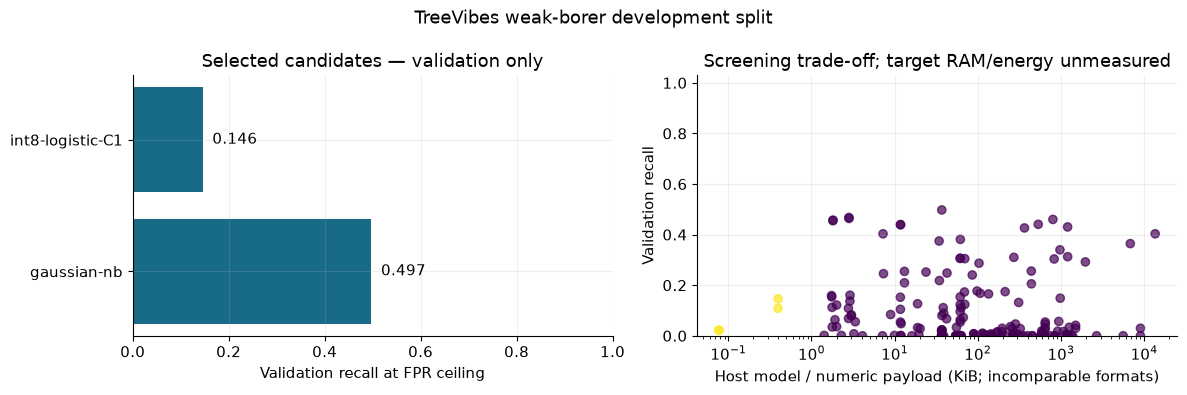

In [15]:
# Compare actual results of compact representations against their information payload.
payloads={'mfcc_flat':1560,'mfcc_summary':104,'mfcc_pca16':64,'mfcc_pca32':128}
communication=[]
for rep,payload in payloads.items():
    subset=track_c[track_c.representation.eq(rep) & track_c.kind.eq('classical')]
    if len(subset):
        best=subset.iloc[0]
        communication.append({'representation':rep,'format':'float32','feature_payload_bytes':payload,
            'recall':best.recall,'fpr':best.fpr,'trial_id':best.trial_id})
for _,row in results[results.kind.eq('portable_int8')].head(1).iterrows():
    communication.append({'representation':'mfcc_flat','format':'int8 + external scale/version',
        'feature_payload_bytes':390,'recall':row.recall,'fpr':row.fpr,'trial_id':row.trial_id})
communication=pd.DataFrame(communication)
communication.to_csv(RUN/'communication_candidates.csv',index=False)
display(communication.round(4))

fig,axes=plt.subplots(1,2,figsize=(12,4))
plot=winners.drop_duplicates('trial_id')
axes[0].barh(np.arange(len(plot)),plot.recall,color='#176B87')
axes[0].set(yticks=np.arange(len(plot)),yticklabels=plot['name'],xlabel='Validation recall at FPR ceiling',xlim=(0,1),
            title='Selected candidates — validation only')
for i,value in enumerate(plot.recall): axes[0].text(min(value+.02,.94),i,f'{value:.3f}',va='center')
axes[1].scatter(results.host_model_bytes/1024,results.recall,c=results.esp_candidate.astype(int),cmap='viridis',alpha=.7)
axes[1].set(xscale='log',xlabel='Host model / numeric payload (KiB; incomparable formats)',ylabel='Validation recall',
            title='Screening trade-off; target RAM/energy unmeasured',ylim=(0,1.03))
fig.suptitle('SYNTHETIC SOFTWARE CHECK' if SYNTHETIC_SMOKE else 'TreeVibes weak-borer development split')
fig.tight_layout(); plt.show()
fig.savefig(RUN/'validation_comparison.png',dpi=150,bbox_inches='tight')


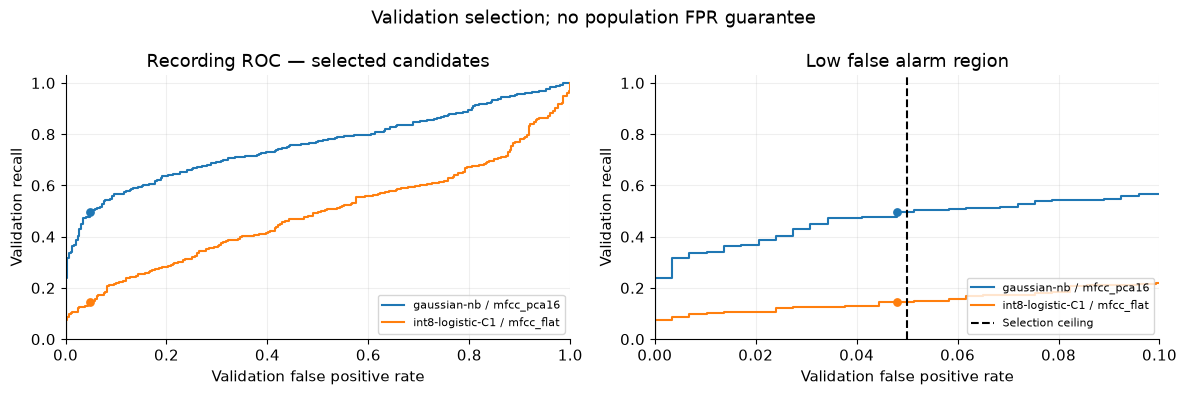

In [16]:
# Full and low-false-alarm views make the selected operating points inspectable.
fig,axes=plt.subplots(1,2,figsize=(12,4))
for _,candidate in winners.drop_duplicates('trial_id').iterrows():
    predictions=pd.read_csv(TRIALS/candidate.trial_id/'validation_predictions.csv')
    fp_rate,true_rate,_=roc_curve(predictions.label,predictions.score)
    label=f"{candidate['name']} / {candidate.representation}"
    for axis in axes:
        axis.plot(fp_rate,true_rate,label=label)
        axis.scatter([candidate.fpr],[candidate.recall],s=28)
for axis in axes:
    axis.set(xlabel='Validation false positive rate',ylabel='Validation recall',ylim=(0,1.03))
axes[0].set(xlim=(0,1),title='Recording ROC — selected candidates')
axes[1].set(xlim=(0,.1),title='Low false alarm region')
axes[1].axvline(FPR_CEILING,color='black',linestyle='--',label='Selection ceiling')
axes[0].legend(fontsize=8,loc='lower right'); axes[1].legend(fontsize=8,loc='lower right')
fig.suptitle('SYNTHETIC SOFTWARE CHECK' if SYNTHETIC_SMOKE else 'Validation selection; no population FPR guarantee')
fig.tight_layout(); plt.show()
fig.savefig(RUN/'validation_roc.png',dpi=150,bbox_inches='tight')


## 10. Board measurements: qualify the ESP32 candidates

Fill the generated CSV with board evidence for the exported **artifact SHA256**, not a similarly named float model. Blank values mean unmeasured. Record board/module, firmware build, compiler settings, feature parity, supported operators, full firmware flash, peak RAM (including audio/FFT/radio), arena, preprocessing + inference latency, and energy.

Energy is measured over the entire acquisition/feature/inference operation. For sampled voltage/current traces integrate `∫V(t)I(t)dt`; with mA and ms, `Σ(V × mA × ms)/1000` gives mJ. Whole-node battery life additionally needs sleep, wakeup, sensing, transmission, retry and regulator losses; it is not derived here. When voltage and current are constant over the measured operation, `energy_mj = voltage_v × average_current_ma × duration_ms / 1000`. Record average current in the CSV; a current/latency average alone can miss peaks.

`target_build_pass`, `feature_parity_pass`, `operators_pass` and measured resource fields are all required before qualification. The budgets above are proposed allocations for your ESP-WROOM-32 system and must be reconciled with its actual firmware and board.


`feature_parity_pass` must cover the full path: MFCC/spectral extraction, input quantization, classifier scores, mean aggregation across all recording windows, and the frozen recording threshold. Check decision agreement on representative recordings; a small score error alone does not establish decision parity.


In [17]:
measurement_path=RUN/'esp32_measurements.csv'
measurement_columns=['trial_id','artifact_sha256','board','firmware_build','evidence_path','target_build_pass',
    'feature_parity_pass','operators_pass','full_firmware_flash_bytes','peak_total_ram_bytes','tensor_arena_bytes',
    'preprocess_plus_inference_ms','operation_energy_mj','voltage_v','average_current_ma','notes']
if not measurement_path.exists():
    pd.DataFrame([{'trial_id':r.trial_id} for _,r in results[results.esp_candidate.eq(True)].iterrows()],
                 columns=measurement_columns).to_csv(measurement_path,index=False)
measurements=pd.read_csv(measurement_path)
qualified=[]
for row in measurements.to_dict('records'):
    trial=TRIALS/str(row['trial_id'])
    artifact=trial/('model.tflite' if (trial/'model.tflite').exists() else 'treevibes_model.h')
    flags=all(str(row.get(k,'')).strip().lower() in {'true','1','yes'} for k in ['target_build_pass','feature_parity_pass','operators_pass'])
    numeric=['full_firmware_flash_bytes','peak_total_ram_bytes','preprocess_plus_inference_ms','operation_energy_mj']
    measured=all(pd.notna(row.get(k)) and float(row[k])>0 for k in numeric)
    evidence=all(pd.notna(row.get(k)) and str(row[k]).strip() for k in ['board','firmware_build','evidence_path'])
    same_artifact=artifact.exists() and str(row.get('artifact_sha256',''))==file_hash(artifact)
    # Firmware flash allocation is separate from the model-only allocation.
    fits=measured and (float(row['peak_total_ram_bytes'])<=ESP_RAM_BUDGET
        and float(row['preprocess_plus_inference_ms'])<=ESP_LATENCY_BUDGET_MS
        and float(row['operation_energy_mj'])<=ESP_ENERGY_BUDGET_MJ
        and float(row['full_firmware_flash_bytes'])<=ESP_FIRMWARE_FLASH_BUDGET)
    candidate=results[results.trial_id.eq(str(row['trial_id']))]
    model_fits=len(candidate)==1 and candidate.iloc[0].get('fits_model_flash_allocation',False)==True
    if flags and measured and evidence and same_artifact and fits and model_fits: qualified.append(str(row['trial_id']))
results['esp_qualified']=results.trial_id.isin(qualified)
results.to_csv(RUN/'leaderboard_validation.csv',index=False)
print('Measured, qualified ESP32 trials:',len(qualified),'| template:',measurement_path)
# Refresh comparison tables after hardware evidence is evaluated.
winners['esp_qualified']=winners.trial_id.isin(qualified)
winners.to_csv(RUN/'track_winners_validation.csv',index=False)
if qualified:
    measured_best=results[results.esp_qualified].iloc[0]
    display(pd.DataFrame([measured_best])[['name','representation','recall','fpr','esp_qualified']])


Measured, qualified ESP32 trials: 0 | template: /Users/khalidhamdan/Documents/ChatGPT/SPD 2 Simulation/outputs/treevibes-training-2026-10-31/treevibes-e473200d753cb0c9/esp32_measurements.csv


## 11. Freeze selections and release the locked test once

Keep `FINAL_TEST=False` during development. This notebook has not run a final benchmark. Use a species-confirmed palm/RPW dataset later for the actual project claim; the held-out TreeVibes labels still measure weak borer annotation agreement.

1. Review source lineage and near-duplicate ancestry across all splits without using model scores. If groups change, regenerate a fresh campaign, not this lock.
2. Write `lineage_review.json` containing the exact manifest/split hashes, `review_complete: true`, reviewer, evidence and `grouping_changed: false`.
3. Copy `selection_draft.json` to `final_selection.json`, edit it to the chosen **few** candidates, and freeze their validation thresholds. Do not add new trials based on test outcomes.
4. Set `FINAL_REVIEW_JSON`, `FINAL_SELECTION_JSON` and `FINAL_TEST=True`. A durable pending marker is written before any test prediction. Interrupted test runs require inspection; they do not silently retry a consumed holdout.

Use multiple independent sites/trees and uncertainty intervals for a research claim; a broad single development search is only a screening experiment.


In [18]:
selection_draft=dict(manifest_sha256=MANIFEST_HASH,split_sha256=SPLIT_HASH,
    label_semantics='weak borer annotations; not species-confirmed RPW',
    selected=[{'trial_id':r.trial_id,'threshold':float(r.threshold)} for _,r in winners.drop_duplicates('trial_id').iterrows()])
write_json(RUN/'selection_draft.json',selection_draft)
review_template=dict(manifest_sha256=MANIFEST_HASH,split_sha256=SPLIT_HASH,review_complete=False,
                     reviewer='',evidence='',grouping_changed=False)
if not (RUN/'lineage_review_template.json').exists(): write_json(RUN/'lineage_review_template.json',review_template)

def predict_bundle(row,bundle,dataset):
    if row['kind']=='classical': return model_scores(bundle['model'],representation(bundle['representation'],dataset))
    if row['kind']=='portable_int8': return portable_scores(bundle,representation(bundle['representation'],dataset))
    if row['kind']=='torch':
        if not TORCH_AVAILABLE: raise RuntimeError('Install torch for selected model')
        net=AudioNet(bundle['name'],bundle['width']).to(device); net.load_state_dict(bundle['state'])
        return neural_scores(net,neural_input(bundle['representation'],dataset),bundle['mean'],bundle['std'])
    if row['kind']=='tflite_int8':
        import tensorflow as tf
        interpreter=tf.lite.Interpreter(model_content=bundle['model_bytes'],num_threads=1); interpreter.allocate_tensors()
        inp=interpreter.get_input_details()[0]; out=interpreter.get_output_details()[0]
        ins,inz=inp['quantization']; outs,outz=out['quantization']; scores=[]
        for x in dataset[bundle['representation']]:
            q=np.clip(np.rint(x/ins+inz),-128,127).astype('int8')[None]
            interpreter.set_tensor(inp['index'],q); interpreter.invoke()
            scores.append(float((float(interpreter.get_tensor(out['index']).reshape(-1)[0])-outz)*outs))
        return np.array(scores)
    raise ValueError('Unknown trial kind')

if FINAL_TEST:
    assert not SYNTHETIC_SMOKE, 'Never promote synthetic fixtures to benchmark evaluation'
    assert FINAL_REVIEW_JSON and FINAL_SELECTION_JSON, 'Supply reviewed lineage and frozen selection files'
    review=json.loads(Path(FINAL_REVIEW_JSON).read_text()); selection=json.loads(Path(FINAL_SELECTION_JSON).read_text())
    for document in [review,selection]:
        assert document['manifest_sha256']==MANIFEST_HASH and document['split_sha256']==SPLIT_HASH
    assert review.get('review_complete') is True and review.get('grouping_changed') is False
    assert review.get('reviewer') and review.get('evidence'), 'Reviewer and evidence required'
    assert 1<=len(selection['selected'])<=4, 'Freeze at most four final project candidates'
    final_marker=RUN/'FINAL_TEST_CONSUMED.json'
    if final_marker.exists():
        raise RuntimeError('Holdout already consumed or evaluation interrupted; inspect existing artifacts before any reuse')
    selected_rows=[]
    for entry in selection['selected']:
        matches=results[results.trial_id.eq(entry['trial_id'])]
        assert len(matches)==1, 'Selected trial not in completed campaign'
        row=matches.iloc[0].to_dict()
        assert float(entry['threshold'])==float(row['threshold']), 'Threshold must stay validation-frozen'
        selected_rows.append(row)
    # Check selected runtime/artifact availability on development data before consuming holdout.
    preflight_bundles={}
    sample={key:value[:1] for key,value in val.items()}
    for row in selected_rows:
        bundle=joblib.load(TRIALS/row['trial_id']/'model.joblib')
        probe=np.asarray(predict_bundle(row,bundle,sample))
        assert probe.shape==(1,) and np.isfinite(probe).all(), 'Selected model inference preflight failed'
        preflight_bundles[row['trial_id']]=bundle
    # Exclusive create prevents concurrent notebook kernels from consuming the test twice.
    with final_marker.open('x') as handle:
        json.dump(dict(status='pending',selection_sha256=file_hash(FINAL_SELECTION_JSON),review_sha256=file_hash(FINAL_REVIEW_JSON)),handle)
    test_ids=np.flatnonzero(manifest.split.to_numpy()=='test')
    test=extract_indices(test_ids)
    final_rows=[]
    for row in selected_rows:
        bundle=preflight_bundles[row['trial_id']]
        stats,predictions=evaluate_scores(predict_bundle(row,bundle,test),test,threshold=row['threshold'])
        predictions.to_csv(RUN/f"test_predictions_{row['trial_id']}.csv",index=False)
        final_rows.append(dict(trial_id=row['trial_id'],name=row['name'],**stats))
    pd.DataFrame(final_rows).to_csv(RUN/'final_test_results.csv',index=False)
    write_json(final_marker,dict(status='complete',selection_sha256=file_hash(FINAL_SELECTION_JSON),review_sha256=file_hash(FINAL_REVIEW_JSON)))
    display(pd.DataFrame(final_rows).round(4))
else:
    print('Locked test untouched. Selection draft:',RUN/'selection_draft.json')


Locked test untouched. Selection draft: /Users/khalidhamdan/Documents/ChatGPT/SPD 2 Simulation/outputs/treevibes-training-2026-10-31/treevibes-e473200d753cb0c9/selection_draft.json


## 12. What to do with the results

- Compare A against C at the same FPR ceiling to quantify the measured cost of the 30×13 input restriction.
- Compare C against the B∩C export candidates to quantify the observed cost of compact inference and quantization.
- Treat B as a shortlist until board measurements qualify the actual exported artifact.
- Compare PCA16/PCA32/26-summary transmission against local classification using measured sensing, processing and LoRa energy. Packet loss/fragmentation can change the best system choice.
- If weak-label performance is insufficient, collect independently labelled palm/RPW recordings, improve source grouping, test temporal multiple-instance learning and pretrained audio embeddings. Those require additional data/lineage or trusted pretrained weights; this notebook does not fabricate their results.

Outputs live under the printed run directory: source and split hashes, feature protocol, per-trial model/checkpoint, validation predictions, failure logs, leaderboards, communication table, C headers/TFLite artifacts, measurement template and frozen-test gates. Never load `joblib`/PyTorch artifacts from untrusted sources.

**Limits:** broad hyperparameter search increases validation optimism. Source/device/site merging may leave few independent groups. Default local training windows are capped for cost; choose `full` to remove that cap. No model, inference-size or MFCC representation filter is applied when selecting A. No hardware current, field RPW recall, battery life, or final-test metric is claimed by this notebook before the corresponding experiment is run.


### Additional project experiments to test next

These are proposed follow-up experiments, not completed results from this run.

| Experiment | What to compare | Project decision |
|---|---|---|
| Pretrained audio embeddings and fine-tuning | PANNs/YAMNet/other trusted audio checkpoints against from-scratch models | Stronger unrestricted baseline; keep input frequency coverage and label lineage explicit |
| Recording-level multiple-instance learning | Mean pooling versus max/attention pooling, using complete recording labels | Whether weak labels hide short useful bursts |
| Tiny quantization-aware networks | PTQ versus QAT for small depthwise CNNs or temporal convolutions | Whether full integer deployment retains recall |
| Distillation and structured pruning | Unrestricted teacher versus compact student/channel-pruned network | Accuracy versus measured total RAM, latency and operation energy |
| Edge/server cascade | Local confidence gate plus server fallback versus local-only and server-only | Overall recall, airtime, packet loss and measured battery energy |
| Radio representation trial | Full int8 MFCC, PCA16/PCA32, summaries and local score packets | End-to-end delivery and energy; include scales, framing, retransmissions and feature computation |
| Sensor/domain robustness | Held-out device/site, gain/noise changes, actual piezo recapture and independently labelled palm data | Whether performance transfers to the project's physical signal chain |
| Acquisition/gating study | Recording duration, schedule and SNR/burst gates | Missed events versus measured sensing, processing and transmission energy |


**Priority ESP32 follow-up:** port and measure the selected PCA16 + Gaussian Naive Bayes pipeline, including its scaler and projection, before treating the portable logistic result as a practical limit. The executed B shortlist used compact logistic exports; optional tiny TensorFlow networks were not run. Its 14.60% recall is not an upper bound on what an ESP32 can achieve. The PCA16/Gaussian pipeline has not been compiled, sized or benchmarked on the board.
